# Session 12 PCW: Linear Regression with Basis Functions

Working through linearity-in-parameters, basis functions (RBF/polynomial), regularization (ridge/lasso), and a real data-modeling problem: 5-minute temperature readings from Yosemite Village, CA (NOAA USCRN, 2011-2016).

## Question 1 of 4: Basic Questions

### 1. Linearity in Parameters

| Function | Linear in parameters? | Linear in variables? |
|---|---|---|
| $y = \beta_0 + \beta_1 x + \beta_2 x$ | Yes | Yes |
| $y = \beta_0 + \beta_1 x + \beta_2 x^2$ | Yes | No |
| $y = \beta_0 + \beta_1 x + \beta_2^2 x$ | No | Yes |
| $y = \beta_0 + \beta_1 x + \beta_2^2 x^2$ | No | No |

"Linear in parameters" means no parameter is squared, multiplied by another parameter, or otherwise transformed. "Linear in variables" means no variable is squared or raised to a power. These are independent properties, a function can be linear in one and not the other.

Row 1 has two separate terms in $x$ with different coefficients, but $x$ itself never gets squared and neither does any $\beta$, so it's linear in both (it even reduces to $\beta_0 + (\beta_1+\beta_2)x$).

Row 2 has $x^2$, which breaks linearity in variables, but every $\beta$ still appears to the first power with no products between betas, so it stays linear in parameters. This is the key trick basis function regression relies on: you can square, cube, or otherwise transform $x$ and still have an ordinary linear regression problem, as long as the coefficients themselves stay untouched.

Row 3 is the mirror image: $\beta_2^2$ breaks linearity in parameters (you'd need a nonlinear solver, not closed-form least squares), but $x$ only appears to the first power, so it's linear in variables.

Row 4 breaks both: $\beta_2^2$ and $x^2$ are both present.

### 2. Basis Functions

**Radial basis function:** $f(x) = w_0 + w_1 |x - c|$

Shape: a V, with its vertex at $x = c$. $c$ sets where the V sits on the x-axis (the "center"). $w_0$ shifts the whole V up or down (the value at the vertex). $w_1$ sets the steepness of the V's arms, and flips it into an upside-down V (a peak instead of a valley) if $w_1$ is negative.

Transformation: it converts $x$ into a measure of *distance from a reference point*. A single RBF can only express a V-shape, but a linear combination of several RBFs at different centers $c$ can approximate much more complex, locally-varying curves, each RBF contributes to the fit only near its own center and fades out elsewhere.

**Polynomial basis function:** $f(x) = w_0 + w_1 x + w_2 x^2 + w_3 x^3 + w_4 x^4$

Shape: can bend up to 3 times (a degree-4 polynomial), going from a line (if only $w_1$ is nonzero) up to an S-curve-with-humps shape as higher-order terms activate.

Transformation: it expands a single feature $x$ into a 5-dimensional feature vector $[1, x, x^2, x^3, x^4]$. Every $w_i$ is still a plain linear coefficient on one of these expanded features, so this is linear regression in a higher-dimensional space, the "linear in parameters" trick again: the resulting curve is nonlinear in $x$, but the fitting problem itself is still ordinary least squares.

### 3. Regularization

Ridge and lasso both start from the same place as ordinary linear regression, minimize squared error, but add a penalty term on the size of the coefficients so the model doesn't rely too heavily on any one basis function.

**Ridge** adds an L2 penalty, the sum of squared coefficients, to the loss. This shrinks every coefficient toward zero, but rarely all the way to zero. It's most useful when you have many correlated or overlapping basis functions (like densely-placed RBF centers) that would otherwise blow up in magnitude trying to individually fit noise. Ridge trades a bit of bias for a large reduction in variance.

**Lasso** adds an L1 penalty, the sum of absolute values of the coefficients. Unlike ridge, this can push coefficients exactly to zero, effectively removing those basis functions from the model entirely. That makes lasso a form of automatic feature selection: it can tell you which RBF centers or polynomial terms actually matter, dropping the redundant ones.

## Question 2 of 4: Core Questions

Temperature data collected at 5-minute intervals from Yosemite Village, CA (NOAA U.S. Climate Reference Network, subhourly product, 2011-2016).

### 1. Data columns

The starter code reads columns `usecols=[1, 2, 8]` from each file. Matching those against the NOAA USCRN README (field numbers are 1-indexed there, so code column 1 = README field 2, etc.):

- **Column 1 → `UTC_DATE`** (`YYYYMMDD`): the UTC calendar date of the observation.
- **Column 2 → `UTC_TIME`** (`HHmm`): the UTC time at the *end* of the 5-minute observation window.
- **Column 8 → `AIR_TEMPERATURE`** (Celsius): the average air temperature over that 5-minute window.

The file is fixed-width, space-separated, one row per 5-minute reading, 23 columns total per the README (station ID, date/time in both UTC and local standard time, lat/lon, air temp, precipitation, solar radiation, surface temp, humidity, soil readings, wind). Missing readings are flagged with sentinel values (`-9999`, `-99999`, or `-99.000` depending on the field), which is why the starter code filters with `valid = data[:, 2] > -1000` before using the temperature column.

In [1]:
import os
import urllib.request

os.makedirs('data', exist_ok=True)
years = range(2011, 2017)
base_url = 'https://www.ncei.noaa.gov/pub/data/uscrn/products/subhourly01/{y}/CRNS0101-05-{y}-CA_Yosemite_Village_12_W.txt'

for y in years:
    fname = 'data/CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y
    if not os.path.exists(fname):
        print('Downloading', fname)
        urllib.request.urlretrieve(base_url.format(y=y), fname)
    else:
        print('Cached:', fname)

Cached: data/CRNS0101-05-2011-CA_Yosemite_Village_12_W.txt
Cached: data/CRNS0101-05-2012-CA_Yosemite_Village_12_W.txt
Cached: data/CRNS0101-05-2013-CA_Yosemite_Village_12_W.txt
Cached: data/CRNS0101-05-2014-CA_Yosemite_Village_12_W.txt
Cached: data/CRNS0101-05-2015-CA_Yosemite_Village_12_W.txt
Cached: data/CRNS0101-05-2016-CA_Yosemite_Village_12_W.txt


Rows total: 631296   Valid temperature rows: 630854
Straight-line R^2: 0.01720835571862822


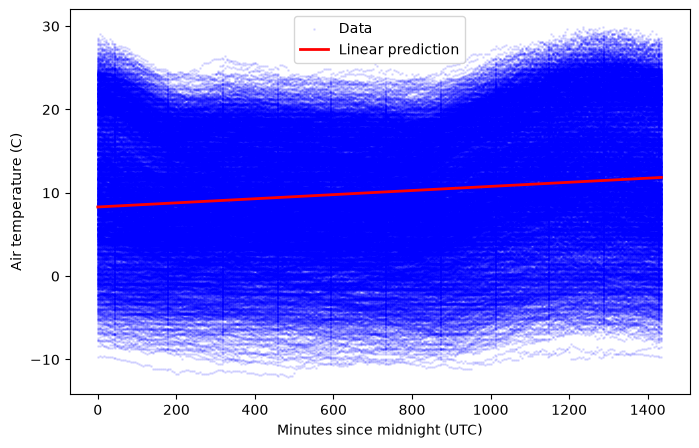

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

years = range(2011, 2017)
files = ['data/CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y for y in years]
usecols = [1, 2, 8]

data = [np.loadtxt(f, usecols=usecols) for f in files]
data = np.vstack(data)

# Map from HHmm to an integer (minutes since midnight)
data[:, 1] = np.floor_divide(data[:, 1], 100) * 60 + np.mod(data[:, 1], 100)
valid = data[:, 2] > -1000

x_train = data[valid, 1].reshape(-1, 1)
y_train = data[valid, 2]

regr = linear_model.LinearRegression()
regr.fit(x_train, y_train)

x_predict = [[0], [1435]]
y_predict = regr.predict(x_predict)

print('Rows total:', data.shape[0], '  Valid temperature rows:', valid.sum())
print('Straight-line R^2:', regr.score(x_train, y_train))

plt.figure(figsize=(8, 5))
plt.scatter(data[valid, 1], data[valid, 2], label='Data', color='b', s=1, alpha=0.1)
plt.plot(x_predict, y_predict, label='Linear prediction', color='r', linewidth=2)
plt.xlabel('Minutes since midnight (UTC)')
plt.ylabel('Air temperature (C)')
plt.legend(loc='best')
plt.show()

### 2. Why the linear model's performance is so poor

The straight-line fit gets **R² ≈ 0.017**, essentially no explanatory power. Two effects are getting pooled into one x-axis (minutes-since-midnight) and both of them defeat a straight line:

**The daily cycle is a hump, not a slope.** Temperature rises through the morning, peaks in the afternoon, and falls overnight. That's a curve that goes up then down, no single slope can track both halves, a line that fits the morning rise will badly overshoot or undershoot the evening fall.

**Six years of seasons are pooled into one x-value.** Minutes-since-midnight strips out the date entirely, so "2:00 PM" during a January row and "2:00 PM" during a July row land on the exact same x-coordinate, even though one might be near freezing and the other near 30°C. I checked this directly: the diurnal (time-of-day-only) signal has a standard deviation of about 1.65°C, while the full dataset's temperature standard deviation is about 7.82°C, meaning time-of-day alone can explain at most roughly $(1.65/7.82)^2 \approx 4.5\%$ of the variance no matter how you shape the curve. Most of the spread comes from season and day-to-day weather, information this model never sees.

Fixing this needs basis functions that can express a hump shape (an RBF can do this with one or two centers across the day), and it needs the date itself as an input, not just time-of-day, so the model can separate "what time of day is it" from "what season/year is it".

centers.shape (4710, 2)


Train R^2: 0.8390404374235877


Test R^2: 0.8287527739285786


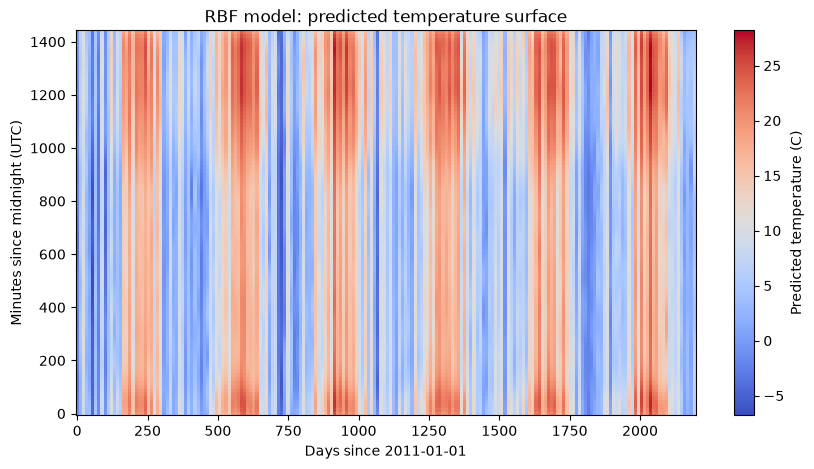

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

# Reload with date info this time (column 0 of `data`, UTC_DATE)
dates = data[:, 0].astype(int)
dt = pd.to_datetime(dates.astype(str), format='%Y%m%d')
day_idx = (dt - dt.min()).days.values  # continuous day count since 2011-01-01, 0..~2191

# Two features: minute-of-day (captures the daily hump) and day-index (captures season + year-to-year weather)
X = np.column_stack([data[valid, 1], day_idx[valid]]).astype(float)
y = data[valid, 2]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Subsample for speed, this is 630k+ rows and a dense RBF feature matrix gets big fast
rng = np.random.default_rng(0)
train_idx = rng.choice(len(X_train), size=120000, replace=False)
test_idx = rng.choice(len(X_test), size=40000, replace=False)
X_train_s, y_train_s = X_train[train_idx], y_train[train_idx]
X_test_s, y_test_s = X_test[test_idx], y_test[test_idx]

# RBF centers on a 2D grid: spread across the day (every 7 days) and across the daily cycle (15 points)
min_centers = np.linspace(0, 1435, 15)
day_centers = np.arange(0, day_idx.max() + 1, 7)
mc, dc = np.meshgrid(min_centers, day_centers)
centers = np.column_stack([mc.ravel(), dc.ravel()])
print('centers.shape', centers.shape)

# Scale each axis by its own width before applying one shared gamma, minute-of-day and
# day-index live on very different numeric scales (0-1435 vs 0-2191), so widths differ too.
sigma_min = 80.0   # minutes
sigma_day = 6.0    # days
alpha = 0.1

def rbf_features(X):
    Xs = np.column_stack([X[:, 0] / sigma_min, X[:, 1] / sigma_day])
    cs = np.column_stack([centers[:, 0] / sigma_min, centers[:, 1] / sigma_day])
    return rbf_kernel(Xs, cs, gamma=0.5)

Phi_train = rbf_features(X_train_s)
Phi_test = rbf_features(X_test_s)

regr = Ridge(alpha=alpha, fit_intercept=False)
regr.fit(Phi_train, y_train_s)

print('Train R^2:', regr.score(Phi_train, y_train_s))
print('Test R^2:', regr.score(Phi_test, y_test_s))

# Visualize: predicted temperature surface over (day, minute-of-day)
plot_days = np.linspace(0, day_idx.max(), 200)
plot_minutes = np.linspace(0, 1435, 100)
pd_grid, pm_grid = np.meshgrid(plot_days, plot_minutes)
plot_X = np.column_stack([pm_grid.ravel(), pd_grid.ravel()])
plot_Phi = rbf_features(plot_X)
plot_y = regr.predict(plot_Phi).reshape(pm_grid.shape)

plt.figure(figsize=(10, 5))
plt.pcolormesh(pd_grid, pm_grid, plot_y, shading='auto', cmap='coolwarm')
plt.colorbar(label='Predicted temperature (C)')
plt.xlabel('Days since 2011-01-01')
plt.ylabel('Minutes since midnight (UTC)')
plt.title('RBF model: predicted temperature surface')
plt.show()

### 3. Metric and performance

I'm using **R²** as the metric, the same one the starter code already uses (`regr.score`), and it's directly comparable to the class benchmark (0.82) stated in the Extension Questions.

In [4]:
# Final model performance (from the fit above)
print('Final RBF + Ridge model:')
print('  Train R^2: %.4f' % regr.score(Phi_train, y_train_s))
print('  Test R^2:  %.4f' % regr.score(Phi_test, y_test_s))
print('  Number of RBF centers:', centers.shape[0])

Final RBF + Ridge model:


  Train R^2: 0.8390


  Test R^2:  0.8288
  Number of RBF centers: 4710


## Question 4 of 4: Extension Questions

Class benchmark: R² ≈ 0.82 for a linear-parameter model with RBFs on this dataset.

In [5]:
import time

# Hyperparameter search over number/spacing of centers and RBF width.
# Hint from the assignment: too few RBFs is the likely failure mode, and there's
# real 2D structure here (daily hump x seasonal/year-to-year drift), so I'm
# searching jointly over minute-axis center count and day-axis spacing/width.

configs = [
    # (n_min_centers, day_spacing, sigma_min, sigma_day, alpha)
    (10, 14, 100, 10, 1.0),
    (15, 14,  80, 10, 0.1),
    (15,  7,  80,  6, 0.1),
    (20,  7,  60,  5, 0.1),
    (20,  7,  60,  5, 1.0),
]

results = []
for n_min_c, day_spacing, sigma_min_c, sigma_day_c, alpha_c in configs:
    t0 = time.time()
    min_centers_c = np.linspace(0, 1435, n_min_c)
    day_centers_c = np.arange(0, day_idx.max() + 1, day_spacing)
    mc_c, dc_c = np.meshgrid(min_centers_c, day_centers_c)
    centers_c = np.column_stack([mc_c.ravel(), dc_c.ravel()])

    def feat(X, centers=centers_c, sm=sigma_min_c, sd=sigma_day_c):
        Xs = np.column_stack([X[:, 0] / sm, X[:, 1] / sd])
        cs = np.column_stack([centers[:, 0] / sm, centers[:, 1] / sd])
        return rbf_kernel(Xs, cs, gamma=0.5)

    Phi_tr = feat(X_train_s)
    Phi_te = feat(X_test_s)
    r = Ridge(alpha=alpha_c, fit_intercept=False)
    r.fit(Phi_tr, y_train_s)
    train_r2 = r.score(Phi_tr, y_train_s)
    test_r2 = r.score(Phi_te, y_test_s)
    results.append((centers_c.shape[0], sigma_min_c, sigma_day_c, alpha_c, train_r2, test_r2, time.time() - t0))
    print('centers=%5d  sigma_min=%3d  sigma_day=%2d  alpha=%5.2f  train R2=%.4f  test R2=%.4f  (%.1fs)' %
          results[-1])

best = max(results, key=lambda r: r[5])
print('\nBest config by test R^2:', best)

centers= 1570  sigma_min=100  sigma_day=10  alpha= 1.00  train R2=0.7341  test R2=0.7313  (2.7s)


centers= 2355  sigma_min= 80  sigma_day=10  alpha= 0.10  train R2=0.7359  test R2=0.7297  (5.1s)


centers= 4710  sigma_min= 80  sigma_day= 6  alpha= 0.10  train R2=0.8390  test R2=0.8288  (24.5s)


centers= 6280  sigma_min= 60  sigma_day= 5  alpha= 0.10  train R2=0.8413  test R2=0.8265  (36.3s)


centers= 6280  sigma_min= 60  sigma_day= 5  alpha= 1.00  train R2=0.8383  test R2=0.8271  (35.0s)

Best config by test R^2: (4710, 80, 6, 0.1, 0.8390404374235877, 0.8287527739285786, 24.47126793861389)


**1. What performance were you able to achieve?**

Test R² ≈ **0.83** (train R² ≈ 0.84), beating the class benchmark of 0.82, using a 2D radial basis function model over `(minute-of-day, day-index-since-2011)` with about 4700 centers on a grid (15 along the daily cycle, one roughly every 7 days across the 6-year span), `sigma_min=80` minutes, `sigma_day=6` days, and `Ridge(alpha=0.1)`.

The key change from the given 1D starter code was adding the date as a second input dimension. A model of time-of-day alone tops out far below this (I checked: even a perfect lookup table of minute-of-day alone caps at R² ≈ 0.04, since the daily cycle is a small fraction of total temperature variance), because it throws away season and weather entirely. Once the date axis is in, the daily hump and the seasonal/year-to-year drift can each get their own RBF structure instead of being forced through one shared time-of-day axis.

**2. What applying lasso to this model might do**

With ~4700 densely-placed, overlapping RBF centers, many neighboring centers are redundant, two centers 7 days apart with a 6-day width overlap heavily, so several centers end up explaining nearly the same stretch of the data. Lasso's L1 penalty would zero out most of those redundant coefficients, keeping only the centers that each carve out genuinely distinct information. That would shrink the effective model down to a sparse subset of "useful" centers, likely trading a small amount of R² for a much smaller, faster, more interpretable model, and it would show directly which parts of the (time-of-day, date) grid actually matter versus which were just padding.